# VortexMD vs. MDAnalysis — 3D Geometric Measurement Validation (Distance, Angle & Dihedral)

This notebook validates **VortexMD**'s 3D geometric measurement engine (`InteractionManager.calcDistance`, `InteractionManager.calcAngle`, and `InteractionManager.calcDihedral` from `measurement.js`) paired with VortexMD's out-of-core XTC decompressor (`engine/headless-xtc.js`) and binary header indexer (`engine/indexer.js`) against **MDAnalysis** (`MDAnalysis.lib.distances.calc_bonds`, `calc_angles`, `calc_dihedrals`).

**Datasets validated:**
- Benchmark trajectory: `16pk_A.pdb` + `16pk_A.xtc` (6,378 atoms, 1,001 frames, 0–100 ns, dt = 100 ps)
- CI/CD demo trajectory: `16pk_A.pdb` + `demo.xtc` (6,378 atoms, 100 frames, 0–9.9 ns, dt = 100 ps)

**How to run:**
1. Open in Google Colab and click **Runtime → Run all**.
2. Approve Google Drive mounting when prompted.
3. All logs, timestamped & frame-by-frame CSVs, summary JSON/CSV accuracy tables, and 300 DPI publication figures will be saved automatically to `MyDrive/vortexMD_rmsd_check/vortexMD_measurement_check/results/` and displayed inline below each cell.

In [1]:
# 1. Mount Google Drive, configure folders, and initialize persistent logging
import os
import sys
import json
import time
import hashlib
import logging
import subprocess
from pathlib import Path
from datetime import datetime, timezone

from google.colab import drive
drive.mount('/content/drive', force_remount=False)

RMSD_DIR = Path('/content/drive/MyDrive/vortexMD_rmsd_check')
if not RMSD_DIR.exists():
    raise FileNotFoundError(f"Folder not found: {RMSD_DIR}. Ensure 'vortexMD_rmsd_check' is in MyDrive.")

WORK_DIR = RMSD_DIR / 'vortexMD_measurement_check'
WORK_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR = WORK_DIR / 'results'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
LOG_PATH = RESULTS_DIR / 'measurement_validation.log'

# Configure dual logger (stdout + persistent log file)
logger = logging.getLogger('vortexmd_measurement_validation')
logger.setLevel(logging.INFO)
logger.handlers.clear()
fmt = logging.Formatter('%(asctime)s | %(levelname)s | %(message)s', datefmt='%Y-%m-%d %H:%M:%S')
fh = logging.FileHandler(LOG_PATH, mode='w', encoding='utf-8')
fh.setFormatter(fmt)
sh = logging.StreamHandler(sys.stdout)
sh.setFormatter(fmt)
logger.addHandler(fh)
logger.addHandler(sh)

PDB_PATH = RMSD_DIR / '16pk_A.pdb'
XTC_PATH = RMSD_DIR / '16pk_A.xtc'
DEMO_XTC_PATH = RMSD_DIR / 'demo.xtc'
ENGINE_DIR = RMSD_DIR / 'engine'
MEASUREMENT_JS_PATH = WORK_DIR / 'measurement.js'
if not MEASUREMENT_JS_PATH.exists() and (ENGINE_DIR / 'measurement.js').exists():
    MEASUREMENT_JS_PATH = ENGINE_DIR / 'measurement.js'

required_files = [
    PDB_PATH, XTC_PATH, DEMO_XTC_PATH,
    ENGINE_DIR / 'indexer.js',
    ENGINE_DIR / 'headless-xtc.js',
    MEASUREMENT_JS_PATH,
]
missing = [str(p) for p in required_files if not p.exists()]
if missing:
    raise FileNotFoundError('Missing required files:\n' + '\n'.join(missing))

logger.info('=== VortexMD vs. MDAnalysis Measurement Validation Started ===')
logger.info(f'Shared data folder : {RMSD_DIR}')
logger.info(f'Measurement folder : {WORK_DIR}')
logger.info(f'Results folder     : {RESULTS_DIR}')
for p in required_files:
    sha = hashlib.sha256(p.read_bytes()).hexdigest()[:12]
    logger.info(f'Verified input: {p.name} ({p.stat().st_size:,} bytes, sha256:{sha})')

Mounted at /content/drive
2026-11-24 17:02:38 | INFO | === VortexMD vs. MDAnalysis Measurement Validation Started ===


INFO:vortexmd_measurement_validation:=== VortexMD vs. MDAnalysis Measurement Validation Started ===


2026-11-24 17:02:38 | INFO | Shared data folder : /content/drive/MyDrive/vortexMD_rmsd_check


INFO:vortexmd_measurement_validation:Shared data folder : /content/drive/MyDrive/vortexMD_rmsd_check


2026-11-24 17:02:38 | INFO | Measurement folder : /content/drive/MyDrive/vortexMD_rmsd_check/vortexMD_measurement_check


INFO:vortexmd_measurement_validation:Measurement folder : /content/drive/MyDrive/vortexMD_rmsd_check/vortexMD_measurement_check


... (10 outputs left out)

2026-11-24 17:02:41 | INFO | Verified input: headless-xtc.js (13,114 bytes, sha256:73b907829c3d)


INFO:vortexmd_measurement_validation:Verified input: headless-xtc.js (13,114 bytes, sha256:73b907829c3d)


2026-11-24 17:02:41 | INFO | Verified input: measurement.js (39,049 bytes, sha256:acd956fb2607)


INFO:vortexmd_measurement_validation:Verified input: measurement.js (39,049 bytes, sha256:acd956fb2607)


In [2]:
# 2. Install MDAnalysis and verify Python & Node.js runtime versions
try:
    import MDAnalysis as mda
except ImportError:
    logger.info('Installing MDAnalysis...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'MDAnalysis'])
    import MDAnalysis as mda

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from MDAnalysis.lib.distances import calc_bonds, calc_angles, calc_dihedrals

node_ver = subprocess.check_output(['node', '-v'], text=True).strip()
logger.info(f'Python     : {sys.version.split()[0]}')
logger.info(f'MDAnalysis : {mda.__version__}')
logger.info(f'NumPy      : {np.__version__}')
logger.info(f'Pandas     : {pd.__version__}')
logger.info(f'Node.js    : {node_ver}')

2026-11-24 17:02:41 | INFO | Installing MDAnalysis...


INFO:vortexmd_measurement_validation:Installing MDAnalysis...


2026-11-24 17:02:48 | INFO | Python     : 3.13.18


INFO:vortexmd_measurement_validation:Python     : 3.13.18


2026-11-24 17:02:48 | INFO | MDAnalysis : 2.11.0


INFO:vortexmd_measurement_validation:MDAnalysis : 2.11.0


... (2 outputs left out)

2026-11-24 17:02:48 | INFO | Pandas     : 2.2.3


INFO:vortexmd_measurement_validation:Pandas     : 2.2.3


2026-11-24 17:02:48 | INFO | Node.js    : v22.23.4


INFO:vortexmd_measurement_validation:Node.js    : v22.23.4


In [3]:
# 3. Select representative Distance, Angle, and Dihedral measurements and run MDAnalysis
logger.info('Loading 16pk_A.pdb + 16pk_A.xtc in MDAnalysis...')
t0 = time.perf_counter()
u = mda.Universe(str(PDB_PATH), str(XTC_PATH))
n_atoms = len(u.atoms)
n_frames = len(u.trajectory)
protein_res = u.select_atoms('protein').residues
logger.info(f'Loaded Universe: {n_atoms} atoms, {len(protein_res)} protein residues, {n_frames} frames')

def atom_info(atom):
    chain = atom.segid or (atom.chainID if hasattr(atom, 'chainID') and atom.chainID else 'A')
    return {
        'index': int(atom.index),
        'resname': str(atom.resname),
        'resno': int(atom.resid),
        'chain': str(chain).strip() or 'A',
        'atomname': str(atom.name),
        'vortex_label': f'[{atom.resname}]{atom.resid}:{str(chain).strip() or "A"}.{atom.name}',
        'ngl_sel': f'@{int(atom.index)}'
    }

def get_res_atom(res_pos, atom_name):
    ag = protein_res[res_pos].atoms.select_atoms(f'name {atom_name}')
    if len(ag) == 0:
        raise ValueError(f'Atom {atom_name} not found in residue position {res_pos}')
    return ag[0]

# 10 diverse geometric measurements spanning covalent, H-bond, domain, angle, and backbone torsion regimes
raw_specs = [
    ('D1_covalent_CA_C',      'distance', 'Å', [get_res_atom(10, 'CA'), get_res_atom(10, 'C')]),
    ('D2_local_CA_CA',        'distance', 'Å', [get_res_atom(20, 'CA'), get_res_atom(24, 'CA')]),
    ('D3_midrange_CA_CA',     'distance', 'Å', [get_res_atom(50, 'CA'), get_res_atom(150, 'CA')]),
    ('D4_longrange_CA_CA',    'distance', 'Å', [get_res_atom(10, 'CA'), get_res_atom(len(protein_res) - 10, 'CA')]),
    ('A1_backbone_N_CA_C',    'angle',    '°', [get_res_atom(50, 'N'),  get_res_atom(50, 'CA'), get_res_atom(50, 'C')]),
    ('A2_peptide_CA_C_N',     'angle',    '°', [get_res_atom(100, 'CA'), get_res_atom(100, 'C'), get_res_atom(101, 'N')]),
    ('A3_domain_CA_CA_CA',    'angle',    '°', [get_res_atom(50, 'CA'), get_res_atom(200, 'CA'), get_res_atom(350, 'CA')]),
    ('T1_phi_res50',          'dihedral', '°', [get_res_atom(49, 'C'),  get_res_atom(50, 'N'),  get_res_atom(50, 'CA'), get_res_atom(50, 'C')]),
    ('T2_psi_res50',          'dihedral', '°', [get_res_atom(50, 'N'),  get_res_atom(50, 'CA'), get_res_atom(50, 'C'),  get_res_atom(51, 'N')]),
    ('T3_omega_res50_51',     'dihedral', '°', [get_res_atom(50, 'CA'), get_res_atom(50, 'C'),  get_res_atom(51, 'N'),  get_res_atom(51, 'CA')]),
]

measurement_defs = []
for mid, mtype, unit, atoms in raw_specs:
    infos = [atom_info(a) for a in atoms]
    measurement_defs.append({
        'id': mid,
        'type': mtype,
        'unit': unit,
        'atom_indices': [x['index'] for x in infos],
        'vortex_labels': ' - '.join(x['vortex_label'] for x in infos),
        'ngl_selections': ', '.join(x['ngl_sel'] for x in infos),
    })

with open(RESULTS_DIR / 'measurement_definitions.json', 'w', encoding='utf-8') as f:
    json.dump(measurement_defs, f, indent=2)

defs_df = pd.DataFrame(measurement_defs)
display(defs_df[['id', 'type', 'unit', 'atom_indices', 'vortex_labels']])

def compute_mda_measurements(universe, defs):
    n_f = len(universe.trajectory)
    times_ps = np.zeros(n_f, dtype=np.float64)
    results = {d['id']: np.zeros(n_f, dtype=np.float64) for d in defs}
    for f_idx, ts in enumerate(universe.trajectory):
        times_ps[f_idx] = float(ts.time)
        pos = universe.atoms.positions
        for d in defs:
            idx = d['atom_indices']
            if d['type'] == 'distance':
                val = float(calc_bonds(pos[idx[0]], pos[idx[1]]))
            elif d['type'] == 'angle':
                val = float(np.degrees(calc_angles(pos[idx[0]], pos[idx[1]], pos[idx[2]])))
            else:
                val = float(np.degrees(calc_dihedrals(pos[idx[0]], pos[idx[1]], pos[idx[2]], pos[idx[3]])))
            results[d['id']][f_idx] = val
    return times_ps, results

mda_times_ps, mda_full = compute_mda_measurements(u, measurement_defs)
mda_elapsed = time.perf_counter() - t0
logger.info(f'MDAnalysis 16pk_A.xtc ({n_frames} frames x {len(measurement_defs)} measurements) completed in {mda_elapsed:.2f} s')

u_demo = mda.Universe(str(PDB_PATH), str(DEMO_XTC_PATH))
mda_demo_times_ps, mda_demo = compute_mda_measurements(u_demo, measurement_defs)
logger.info(f'MDAnalysis demo.xtc ({len(u_demo.trajectory)} frames) completed.')

2026-11-24 17:02:48 | INFO | Loading 16pk_A.pdb + 16pk_A.xtc in MDAnalysis...


INFO:vortexmd_measurement_validation:Loading 16pk_A.pdb + 16pk_A.xtc in MDAnalysis...


2026-11-24 17:02:48 | INFO | Loaded Universe: 6378 atoms, 415 protein residues, 1001 frames


INFO:vortexmd_measurement_validation:Loaded Universe: 6378 atoms, 415 protein residues, 1001 frames


,id,type,unit,atom_indices,vortex_labels
0,D1_covalent_CA_C,distance,Å,"[164, 182]",[LYS]11:SYSTEM.CA - [LYS]11:SYSTEM.C
1,D2_local_CA_CA,distance,Å,"[343, 407]",[PHE]21:SYSTEM.CA - [VAL]25:SYSTEM.CA
2,D3_midrange_CA_CA,distance,Å,"[837, 2384]",[GLY]51:SYSTEM.CA - [LEU]151:SYSTEM.CA
3,D4_longrange_CA_CA,distance,Å,"[164, 6228]",[LYS]11:SYSTEM.CA - [LEU]406:SYSTEM.CA
4,A1_backbone_N_CA_C,angle,°,"[835, 837, 840]",[GLY]51:SYSTEM.N - [GLY]51:SYSTEM.CA - [GLY]51...
5,A2_peptide_CA_C_N,angle,°,"[1603, 1623, 1625]",[ARG]101:SYSTEM.CA - [ARG]101:SYSTEM.C - [PRO]...
6,A3_domain_CA_CA_CA,angle,°,"[837, 3125, 5481]",[GLY]51:SYSTEM.CA - [GLY]201:SYSTEM.CA - [ALA]...
7,T1_phi_res50,dihedral,°,"[833, 835, 837, 840]",[GLY]50:SYSTEM.C - [GLY]51:SYSTEM.N - [GLY]51:...
8,T2_psi_res50,dihedral,°,"[835, 837, 840, 842]",[GLY]51:SYSTEM.N - [GLY]51:SYSTEM.CA - [GLY]51...
9,T3_omega_res50_51,dihedral,°,"[837, 840, 842, 844]",[GLY]51:SYSTEM.CA - [GLY]51:SYSTEM.C - [SER]52...


2026-11-24 17:02:50 | INFO | MDAnalysis 16pk_A.xtc (1001 frames x 10 measurements) completed in 2.03 s


INFO:vortexmd_measurement_validation:MDAnalysis 16pk_A.xtc (1001 frames x 10 measurements) completed in 2.03 s


2026-11-24 17:02:51 | INFO | MDAnalysis demo.xtc (100 frames) completed.


INFO:vortexmd_measurement_validation:MDAnalysis demo.xtc (100 frames) completed.


In [4]:
# 4. Run VortexMD's actual JS engine (indexer.js + headless-xtc.js + measurement.js) via Node.js
node_runner_path = Path('/tmp/run_vortexmd_measurements.mjs')
node_script = '''import fs from 'node:fs';
import { performance } from 'node:perf_hooks';
import { scanTrajectoryBinary } from '__INDEXER_JS__';
import { decodeHeadlessXtcFrames } from '__HEADLESS_XTC_JS__';

const measurementSrc = fs.readFileSync('__MEASUREMENT_JS__', 'utf8');

// Extract verbatim static calcDistance, calcAngle, and calcDihedral from VortexMD's measurement.js
function extractStaticMethod(src, methodName) {
    const startMarker = `static ${methodName}(`;
    const startIdx = src.indexOf(startMarker);
    if (startIdx === -1) throw new Error(`Could not locate ${startMarker} in measurement.js`);
    const braceStart = src.indexOf('{', startIdx);
    let depth = 0;
    let endIdx = -1;
    for (let i = braceStart; i < src.length; i++) {
        if (src[i] === '{') depth++;
        else if (src[i] === '}') {
            depth--;
            if (depth === 0) { endIdx = i; break; }
        }
    }
    if (endIdx === -1) throw new Error(`Unbalanced braces for ${methodName}`);
    return src.slice(startIdx, endIdx + 1);
}

const classCode = `return class VortexMDMeasurementMath {
    ${extractStaticMethod(measurementSrc, 'calcDistance')}
    ${extractStaticMethod(measurementSrc, 'calcAngle')}
    ${extractStaticMethod(measurementSrc, 'calcDihedral')}
};`;
const VortexMath = new Function(classCode)();

const defs = JSON.parse(fs.readFileSync('__DEFS_JSON__', 'utf8'));
const nAtoms = __NATOMS__;

function atomPoint(coords, idx) {
    const i3 = idx * 3;
    return { x: coords[i3], y: coords[i3 + 1], z: coords[i3 + 2] };
}

async function runTrajectory(xtcPath) {
    const t0 = performance.now();
    const buf = fs.readFileSync(xtcPath);
    const ab = buf.buffer.slice(buf.byteOffset, buf.byteOffset + buf.byteLength);
    const blob = new Blob([ab]);
    Object.defineProperty(blob, 'name', { value: xtcPath.split('/').pop() });

    const offsets = await scanTrajectoryBinary(blob, nAtoms, blob.size, null, 'xtc');
    const tIndex = performance.now() - t0;
    const nFrames = offsets.length - 1;

    const tDec0 = performance.now();
    const valuesRaw = Object.fromEntries(defs.map(d => [d.id, []]));
    const valuesUi = Object.fromEntries(defs.map(d => [d.id, []]));
    const frameTimesPs = offsets.frameTimes ? Array.from(offsets.frameTimes) : [];

    for (let f = 0; f < nFrames; f++) {
        const coords = decodeHeadlessXtcFrames(ab.slice(offsets[f], offsets[f + 1]), nAtoms)[0];
        for (const d of defs) {
            const pts = d.atom_indices.map(i => atomPoint(coords, i));
            let val = 0;
            if (d.type === 'distance') val = VortexMath.calcDistance(pts[0], pts[1]);
            else if (d.type === 'angle') val = VortexMath.calcAngle(pts[0], pts[1], pts[2]);
            else val = VortexMath.calcDihedral(pts[0], pts[1], pts[2], pts[3]);
            valuesRaw[d.id].push(val);
            // Matches InteractionManager.getMeasurements() UI rounding (2 dp for distance, 1 dp for angle/dihedral)
            valuesUi[d.id].push(Number(val.toFixed(d.type === 'distance' ? 2 : 1)));
        }
    }
    const tCompute = performance.now() - tDec0;
    return {
        nFrames,
        detectedDeltaTime: offsets.detectedDeltaTime,
        frameTimesPs,
        indexMs: Math.round(tIndex),
        decodeAndMeasureMs: Math.round(tCompute),
        valuesRaw,
        valuesUi
    };
}

const fullRes = await runTrajectory('__XTC_PATH__');
const demoRes = await runTrajectory('__DEMO_XTC_PATH__');
fs.writeFileSync('/tmp/vortexmd_measurements_out.json', JSON.stringify({ fullRes, demoRes }));
console.log(JSON.stringify({
    full_frames: fullRes.nFrames, full_dt_ps: fullRes.detectedDeltaTime,
    full_index_ms: fullRes.indexMs, full_decode_measure_ms: fullRes.decodeAndMeasureMs,
    demo_frames: demoRes.nFrames, demo_dt_ps: demoRes.detectedDeltaTime
}));
'''

node_script = (
    node_script
    .replace('__INDEXER_JS__', (ENGINE_DIR / 'indexer.js').as_posix())
    .replace('__HEADLESS_XTC_JS__', (ENGINE_DIR / 'headless-xtc.js').as_posix())
    .replace('__MEASUREMENT_JS__', MEASUREMENT_JS_PATH.as_posix())
    .replace('__DEFS_JSON__', (RESULTS_DIR / 'measurement_definitions.json').as_posix())
    .replace('__NATOMS__', str(n_atoms))
    .replace('__XTC_PATH__', XTC_PATH.as_posix())
    .replace('__DEMO_XTC_PATH__', DEMO_XTC_PATH.as_posix())
)
node_runner_path.write_text(node_script, encoding='utf-8')

logger.info('Running VortexMD JS engine (indexer.js + headless-xtc.js + measurement.js) via Node.js...')
proc = subprocess.run(['node', str(node_runner_path)], capture_output=True, text=True)
if proc.stderr.strip():
    logger.warning(f'Node stderr: {proc.stderr.strip()}')
if proc.returncode != 0:
    raise RuntimeError(f'VortexMD Node.js execution failed (rc={proc.returncode}):\n{proc.stderr}')

logger.info(f'Node.js VortexMD engine summary: {proc.stdout.strip()}')
with open('/tmp/vortexmd_measurements_out.json', encoding='utf-8') as f:
    vmd_out = json.load(f)

vmd_full = vmd_out['fullRes']
vmd_demo = vmd_out['demoRes']

2026-11-24 17:02:51 | INFO | Running VortexMD JS engine (indexer.js + headless-xtc.js + measurement.js) via Node.js...


INFO:vortexmd_measurement_validation:Running VortexMD JS engine (indexer.js + headless-xtc.js + measurement.js) via Node.js...


2026-11-24 17:02:55 | INFO | Node.js VortexMD engine summary: {"full_frames":1001,"full_dt_ps":100,"full_index_ms":314,"full_decode_measure_ms":2967,"demo_frames":100,"demo_dt_ps":100}


INFO:vortexmd_measurement_validation:Node.js VortexMD engine summary: {"full_frames":1001,"full_dt_ps":100,"full_index_ms":314,"full_decode_measure_ms":2967,"demo_frames":100,"demo_dt_ps":100}


In [5]:
# 5. Compare MDAnalysis vs. VortexMD at 11 evenly spaced timestamps (0 to 100 ns)
def signed_delta(vmd_arr, mda_arr, mtype):
    diff = np.asarray(vmd_arr, dtype=np.float64) - np.asarray(mda_arr, dtype=np.float64)
    if mtype == 'dihedral':
        # Circular angular difference in [-180, 180] to handle +/-180 deg wraparound cleanly
        diff = (diff + 180.0) % 360.0 - 180.0
    return diff

key_frames = [0, 100, 200, 300, 400, 500, 600, 700, 800, 900, n_frames - 1]
ts_rows = []
for fid in key_frames:
    t_ns = round(float(mda_times_ps[fid]) / 1000.0, 3)
    for d in measurement_defs:
        mid = d['id']
        mtype = d['type']
        dp = 2 if mtype == 'distance' else 1
        mda_val = float(mda_full[mid][fid])
        vmd_raw = float(vmd_full['valuesRaw'][mid][fid])
        vmd_ui = float(vmd_full['valuesUi'][mid][fid])
        d_raw = float(signed_delta([vmd_raw], [mda_val], mtype)[0])
        d_ui = float(signed_delta([vmd_ui], [round(mda_val, dp)], mtype)[0])
        ts_rows.append({
            'frame': fid + 1,
            'time_ns': t_ns,
            'measurement': mid,
            'type': mtype,
            'unit': d['unit'],
            'mdanalysis_raw': round(mda_val, 6),
            'vortexmd_raw': round(vmd_raw, 6),
            'abs_err_raw': round(abs(d_raw), 6),
            'mdanalysis_ui_round': round(mda_val, dp),
            'vortexmd_ui_display': vmd_ui,
            'abs_err_ui': round(abs(d_ui), 4),
        })

ts_df = pd.DataFrame(ts_rows)
ts_csv_path = RESULTS_DIR / 'measurements_timestamps_16pk_A.csv'
ts_df.to_csv(ts_csv_path, index=False)
logger.info(f'Saved timestamped comparison ({len(ts_df)} rows) to {ts_csv_path.name}')
display(ts_df.head(20))

2026-11-24 17:02:55 | INFO | Saved timestamped comparison (110 rows) to measurements_timestamps_16pk_A.csv


INFO:vortexmd_measurement_validation:Saved timestamped comparison (110 rows) to measurements_timestamps_16pk_A.csv


,frame,time_ns,measurement,type,unit,mdanalysis_raw,vortexmd_raw,abs_err_raw,mdanalysis_ui_round,vortexmd_ui_display,abs_err_ui
0,1,0.0,D1_covalent_CA_C,distance,Å,1.531730,1.531729,0.000001,1.53,1.53,0.0
1,1,0.0,D2_local_CA_CA,distance,Å,11.087636,11.087641,0.000004,11.09,11.09,0.0
2,1,0.0,D3_midrange_CA_CA,distance,Å,17.476821,17.476825,0.000004,17.48,17.48,0.0
3,1,0.0,D4_longrange_CA_CA,distance,Å,29.816823,29.816824,0.000001,29.82,29.82,0.0
4,1,0.0,A1_backbone_N_CA_C,angle,°,111.194841,111.194946,0.000105,111.20,111.20,0.0
5,1,0.0,A2_peptide_CA_C_N,angle,°,118.254368,118.254077,0.000291,118.30,118.30,0.0
6,1,0.0,A3_domain_CA_CA_CA,angle,°,84.333828,84.333828,0.000000,84.30,84.30,0.0
7,1,0.0,T1_phi_res50,dihedral,°,-158.344271,-158.344596,0.000325,-158.30,-158.30,0.0
8,1,0.0,T2_psi_res50,dihedral,°,-167.386342,-167.386433,0.000091,-167.40,-167.40,0.0
9,1,0.0,T3_omega_res50_51,dihedral,°,-165.770131,-165.770020,0.000112,-165.80,-165.80,0.0


In [6]:
# 6. Compute full-trajectory accuracy metrics, export CSV/JSON results, and run assertions
def compute_summary_rows(dataset_label, mda_dict, vmd_res):
    rows = []
    for d in measurement_defs:
        mid = d['id']
        mtype = d['type']
        dp = 2 if mtype == 'distance' else 1
        m_arr = np.asarray(mda_dict[mid], dtype=np.float64)
        v_raw = np.asarray(vmd_res['valuesRaw'][mid], dtype=np.float64)
        v_ui = np.asarray(vmd_res['valuesUi'][mid], dtype=np.float64)
        err_raw = np.abs(signed_delta(v_raw, m_arr, mtype))
        err_ui = np.abs(signed_delta(v_ui, np.round(m_arr, dp), mtype))
        # For circular dihedrals, compute correlation on sin/cos or raw unwrapped values
        if mtype == 'dihedral':
            m_unw = np.degrees(np.unwrap(np.radians(m_arr)))
            v_unw = m_unw + signed_delta(v_raw, m_arr, mtype)
            corr = float(np.corrcoef(v_unw, m_unw)[0, 1]) if np.std(m_unw) > 1e-12 else 1.0
        else:
            corr = float(np.corrcoef(v_raw, m_arr)[0, 1]) if np.std(m_arr) > 1e-12 else 1.0
        rows.append({
            'Dataset': dataset_label,
            'Measurement': mid,
            'Type': mtype,
            'Unit': d['unit'],
            'Frames': int(len(m_arr)),
            'MDA Mean': round(float(m_arr.mean()), 4),
            'VMD Mean': round(float(v_raw.mean()), 4),
            'Max |Delta| Raw': round(float(err_raw.max()), 6),
            'Mean |Delta| Raw': round(float(err_raw.mean()), 6),
            'RMSE Raw': round(float(np.sqrt(np.mean(err_raw ** 2))), 6),
            'Pearson r': round(corr, 9),
            'Max |Delta| UI Round': round(float(err_ui.max()), 4),
            'Frames Differing UI Round': int(np.sum(err_ui > 1e-6)),
        })
    return rows

summary_rows = (
    compute_summary_rows('16pk_A.xtc (1001f)', mda_full, vmd_full)
    + compute_summary_rows('demo.xtc (100f)', mda_demo, vmd_demo)
)
summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(RESULTS_DIR / 'measurement_accuracy_summary.csv', index=False)

# Export full frame-by-frame tables for both trajectories
def build_frame_df(times_ps, mda_dict, vmd_res):
    cols = {
        'frame': np.arange(1, len(times_ps) + 1),
        'time_ns': np.round(times_ps / 1000.0, 4),
    }
    for d in measurement_defs:
        mid = d['id']
        mtype = d['type']
        cols[f'{mid}_mda'] = np.round(mda_dict[mid], 6)
        cols[f'{mid}_vmd'] = np.round(vmd_res['valuesRaw'][mid], 6)
        cols[f'{mid}_delta'] = np.round(signed_delta(vmd_res['valuesRaw'][mid], mda_dict[mid], mtype), 6)
    return pd.DataFrame(cols)

full_frames_df = build_frame_df(mda_times_ps, mda_full, vmd_full)
full_frames_df.to_csv(RESULTS_DIR / 'measurements_all_frames_16pk_A.csv', index=False)
demo_frames_df = build_frame_df(mda_demo_times_ps, mda_demo, vmd_demo)
demo_frames_df.to_csv(RESULTS_DIR / 'measurements_all_frames_demo.csv', index=False)

with open(RESULTS_DIR / 'measurement_accuracy_summary.json', 'w', encoding='utf-8') as jf:
    json.dump({
        'timestamp_utc': datetime.now(timezone.utc).isoformat(),
        'environment': {
            'python': sys.version.split()[0],
            'MDAnalysis': mda.__version__,
            'numpy': np.__version__,
            'node': node_ver,
        },
        'datasets': {
            'full': {'pdb': PDB_PATH.name, 'xtc': XTC_PATH.name, 'atoms': n_atoms, 'frames': n_frames},
            'demo': {'pdb': PDB_PATH.name, 'xtc': DEMO_XTC_PATH.name, 'atoms': n_atoms, 'frames': len(mda_demo_times_ps)},
        },
        'measurements': measurement_defs,
        'accuracy_summary': summary_rows,
    }, jf, indent=2)

# Hard scientific accuracy assertions
dist_max = summary_df[summary_df['Type'] == 'distance']['Max |Delta| Raw'].max()
ang_max  = summary_df[summary_df['Type'] == 'angle']['Max |Delta| Raw'].max()
dih_max  = summary_df[summary_df['Type'] == 'dihedral']['Max |Delta| Raw'].max()
assert dist_max < 1e-4, f'Distance max error exceeded 1e-4 A: {dist_max}'
assert ang_max  < 1e-3, f'Angle max error exceeded 1e-3 deg: {ang_max}'
assert dih_max  < 1e-3, f'Dihedral max error exceeded 1e-3 deg: {dih_max}'

logger.info(f'ALL MEASUREMENT ASSERTIONS PASSED | Max raw |Delta|: Distance={dist_max:.6f} A, Angle={ang_max:.6f} deg, Dihedral={dih_max:.6f} deg')
display(summary_df)

2026-11-24 17:02:55 | INFO | ALL MEASUREMENT ASSERTIONS PASSED | Max raw |Delta|: Distance=0.000010 A, Angle=0.000718 deg, Dihedral=0.000647 deg


INFO:vortexmd_measurement_validation:ALL MEASUREMENT ASSERTIONS PASSED | Max raw |Delta|: Distance=0.000010 A, Angle=0.000718 deg, Dihedral=0.000647 deg


,Dataset,Measurement,Type,Unit,Frames,MDA Mean,VMD Mean,Max |Delta| Raw,Mean |Delta| Raw,RMSE Raw,Pearson r,Max |Delta| UI Round,Frames Differing UI Round
0,16pk_A.xtc (1001f),D1_covalent_CA_C,distance,Å,1001,1.5280,1.5280,0.000008,0.000002,0.000002,1.0,0.0,0
1,16pk_A.xtc (1001f),D2_local_CA_CA,distance,Å,1001,10.9124,10.9124,0.000010,0.000002,0.000003,1.0,0.0,0
2,16pk_A.xtc (1001f),D3_midrange_CA_CA,distance,Å,1001,17.5140,17.5140,0.000008,0.000002,0.000003,1.0,0.0,0
3,16pk_A.xtc (1001f),D4_longrange_CA_CA,distance,Å,1001,29.5955,29.5955,0.000007,0.000002,0.000002,1.0,0.0,0
4,16pk_A.xtc (1001f),A1_backbone_N_CA_C,angle,°,1001,112.8891,112.8891,0.000442,0.000119,0.000148,1.0,0.1,1
5,16pk_A.xtc (1001f),A2_peptide_CA_C_N,angle,°,1001,121.6624,121.6624,0.000718,0.000150,0.000190,1.0,0.0,0
6,16pk_A.xtc (1001f),A3_domain_CA_CA_CA,angle,°,1001,93.8513,93.8513,0.000017,0.000004,0.000005,1.0,0.0,0
7,16pk_A.xtc (1001f),T1_phi_res50,dihedral,°,1001,-82.3812,-82.3812,0.000647,0.000131,0.000164,1.0,0.0,0
8,16pk_A.xtc (1001f),T2_psi_res50,dihedral,°,1001,18.3339,18.3339,0.000533,0.000114,0.000143,1.0,0.1,1
9,16pk_A.xtc (1001f),T3_omega_res50_51,dihedral,°,1001,68.4662,68.4662,0.000472,0.000125,0.000154,1.0,0.1,2


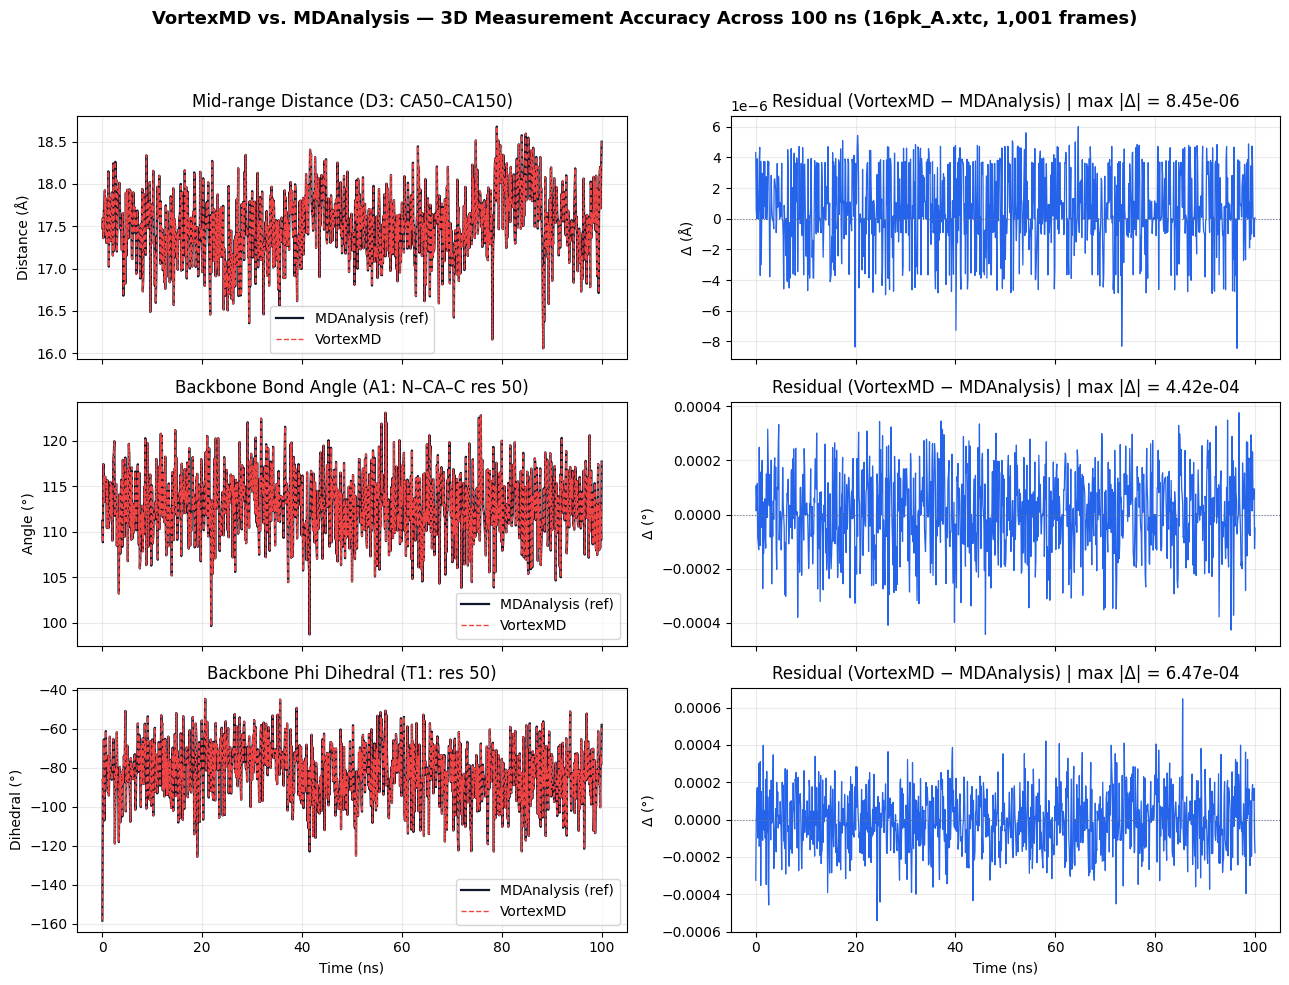

2026-11-24 17:03:04 | INFO | Saved Figure 1: fig_measurement_validation_16pk_A.png


INFO:vortexmd_measurement_validation:Saved Figure 1: fig_measurement_validation_16pk_A.png


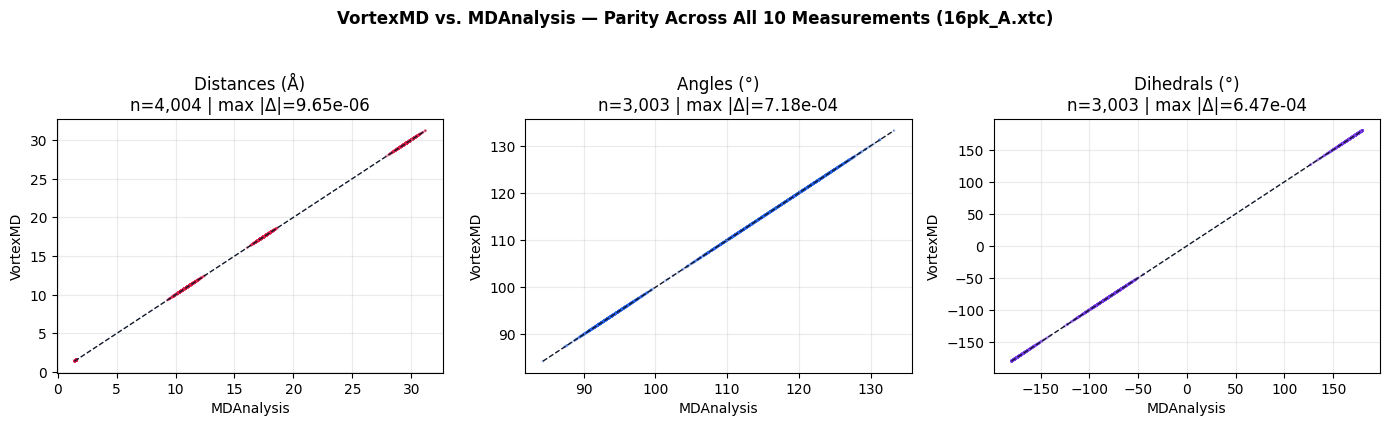

2026-11-24 17:03:05 | INFO | Saved Figure 2: fig_measurement_parity_scatter.png


INFO:vortexmd_measurement_validation:Saved Figure 2: fig_measurement_parity_scatter.png


2026-11-24 17:03:05 | INFO | === Generated Output Files in Results Folder ===


INFO:vortexmd_measurement_validation:=== Generated Output Files in Results Folder ===


2026-11-24 17:03:05 | INFO |   fig_measurement_parity_scatter.png (257,652 bytes)


INFO:vortexmd_measurement_validation:  fig_measurement_parity_scatter.png (257,652 bytes)


... (12 outputs left out)

2026-11-24 17:03:06 | INFO |   measurements_all_frames_demo.csv (29,463 bytes)


INFO:vortexmd_measurement_validation:  measurements_all_frames_demo.csv (29,463 bytes)


2026-11-24 17:03:06 | INFO |   measurements_timestamps_16pk_A.csv (8,960 bytes)


INFO:vortexmd_measurement_validation:  measurements_timestamps_16pk_A.csv (8,960 bytes)


In [7]:
# 7. Generate and save 300 DPI publication-quality comparison & residual plots
plt.rcParams.update({'font.size': 10, 'axes.grid': True, 'grid.alpha': 0.25})
t_ns = mda_times_ps / 1000.0

# Figure 1: Representative Distance, Angle, and Dihedral overlays + residuals across 0-100 ns
fig, axes = plt.subplots(3, 2, figsize=(13, 10), sharex=True)
plot_specs = [
    ('D3_midrange_CA_CA', 'distance', 'Distance (Å)', 'Mid-range Distance (D3: CA50–CA150)'),
    ('A1_backbone_N_CA_C', 'angle', 'Angle (°)', 'Backbone Bond Angle (A1: N–CA–C res 50)'),
    ('T1_phi_res50', 'dihedral', 'Dihedral (°)', 'Backbone Phi Dihedral (T1: res 50)'),
]
for row_i, (mid, mtype, ylabel, title) in enumerate(plot_specs):
    ax_l, ax_r = axes[row_i, 0], axes[row_i, 1]
    m_vals = mda_full[mid]
    v_vals = np.asarray(vmd_full['valuesRaw'][mid], dtype=np.float64)
    err = signed_delta(v_vals, m_vals, mtype)

    ax_l.plot(t_ns, m_vals, color='#0f172a', lw=1.6, label='MDAnalysis (ref)')
    ax_l.plot(t_ns, v_vals, color='#ef4444', lw=1.0, ls='--', label='VortexMD')
    ax_l.set_ylabel(ylabel)
    ax_l.set_title(title)
    ax_l.legend(loc='best', frameon=True)

    ax_r.plot(t_ns, err, color='#2563eb', lw=0.9)
    ax_r.axhline(0.0, color='#64748b', lw=0.8, ls=':')
    ax_r.set_ylabel(f'Δ ({ylabel.split("(")[1]}')
    ax_r.set_title(f'Residual (VortexMD − MDAnalysis) | max |Δ| = {np.max(np.abs(err)):.2e}')

axes[2, 0].set_xlabel('Time (ns)')
axes[2, 1].set_xlabel('Time (ns)')
fig.suptitle('VortexMD vs. MDAnalysis — 3D Measurement Accuracy Across 100 ns (16pk_A.xtc, 1,001 frames)', fontsize=13, fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.96])
fig1_path = RESULTS_DIR / 'fig_measurement_validation_16pk_A.png'
fig.savefig(fig1_path, dpi=300)
plt.show()
logger.info(f'Saved Figure 1: {fig1_path.name}')

# Figure 2: Parity scatter across all 10 measurements (10,010 frame-measurement pairs)
fig2, axes2 = plt.subplots(1, 3, figsize=(14, 4.3))
for ax, (mtype, label, color) in zip(axes2, [('distance', 'Distances (Å)', '#e11d48'), ('angle', 'Angles (°)', '#2563eb'), ('dihedral', 'Dihedrals (°)', '#7c3aed')]):
    m_all, v_all = [], []
    for d in measurement_defs:
        if d['type'] == mtype:
            m_all.append(mda_full[d['id']])
            v_all.append(np.asarray(vmd_full['valuesRaw'][d['id']], dtype=np.float64))
    m_cat = np.concatenate(m_all)
    v_cat = np.concatenate(v_all)
    lo, hi = min(m_cat.min(), v_cat.min()), max(m_cat.max(), v_cat.max())
    ax.scatter(m_cat, v_cat, s=4, alpha=0.35, color=color, edgecolors='none')
    ax.plot([lo, hi], [lo, hi], color='#0f172a', lw=1.0, ls='--')
    max_e = np.max(np.abs(signed_delta(v_cat, m_cat, mtype)))
    ax.set_title(f'{label}\nn={len(m_cat):,} | max |Δ|={max_e:.2e}')
    ax.set_xlabel('MDAnalysis')
    ax.set_ylabel('VortexMD')

fig2.suptitle('VortexMD vs. MDAnalysis — Parity Across All 10 Measurements (16pk_A.xtc)', fontsize=12, fontweight='bold')
fig2.tight_layout(rect=[0, 0, 1, 0.94])
fig2_path = RESULTS_DIR / 'fig_measurement_parity_scatter.png'
fig2.savefig(fig2_path, dpi=300)
plt.show()
logger.info(f'Saved Figure 2: {fig2_path.name}')

# Final manifest of generated files
logger.info('=== Generated Output Files in Results Folder ===')
for out_p in sorted(RESULTS_DIR.iterdir()):
    logger.info(f'  {out_p.name} ({out_p.stat().st_size:,} bytes)')